In [1]:
import pandas as pd
import numpy as np
import kagglehub
import os
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

c:\Users\aymen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("maqdadali/mental-health-risk-prediction-dataset-students")

df = pd.read_csv(os.path.join(path, "student_mental_health.csv"))
# print("Dataset shape:", df.shape)
print("Dataset columns:", df.columns)
# print(df.info())
# print(df.describe())
# print(df.isnull().sum())

Dataset columns: Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours',
       'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
       'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='str')


In [ ]:
df = df.drop(columns=['Student_ID', 'Gender'])

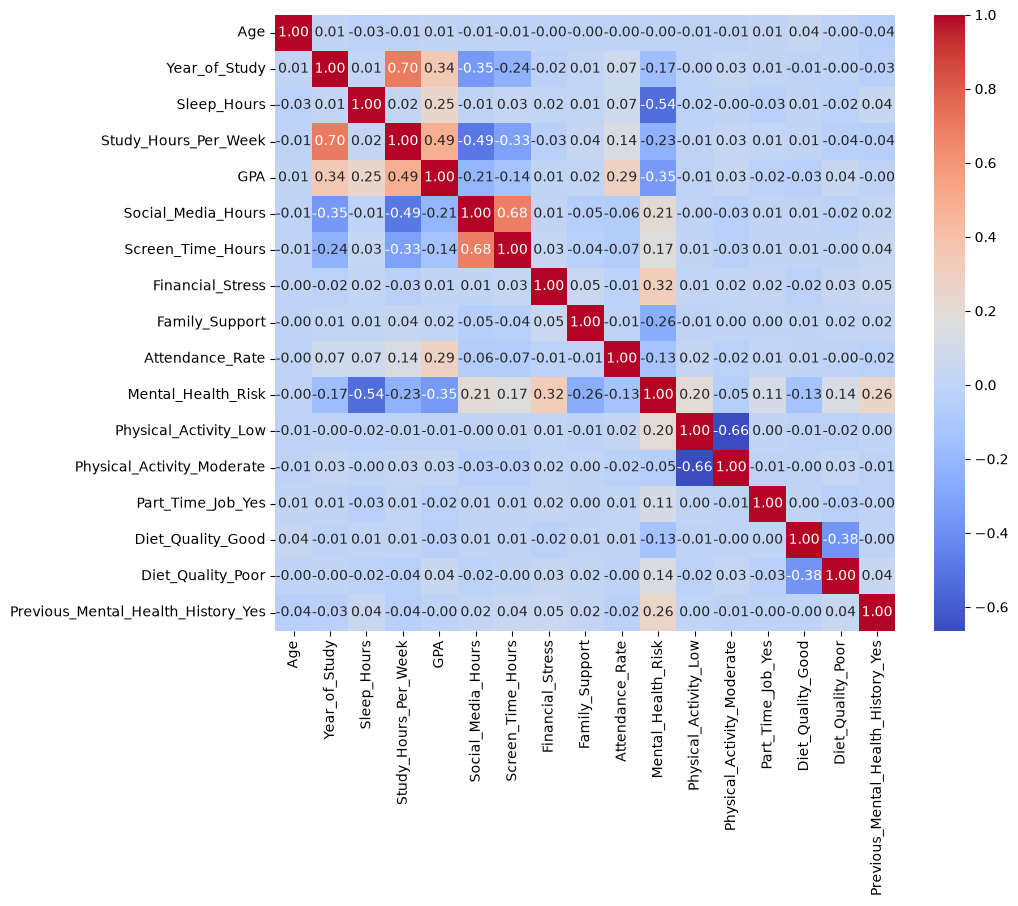

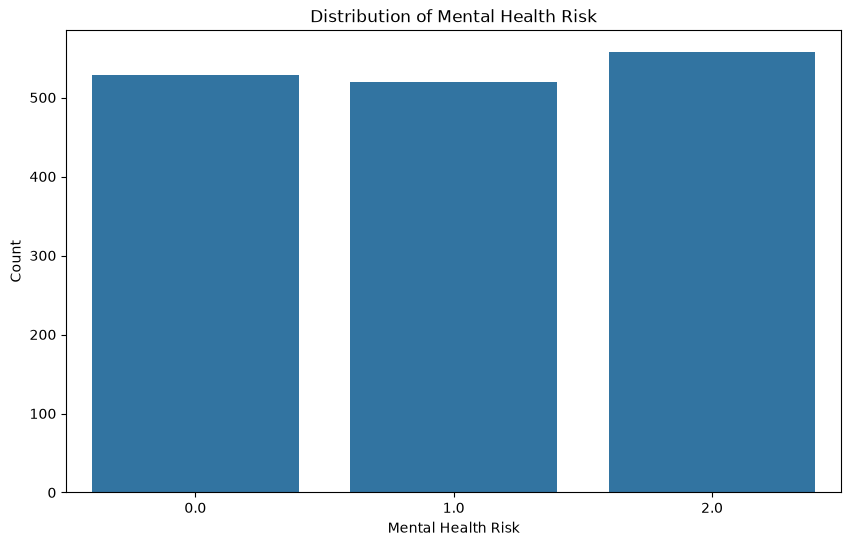

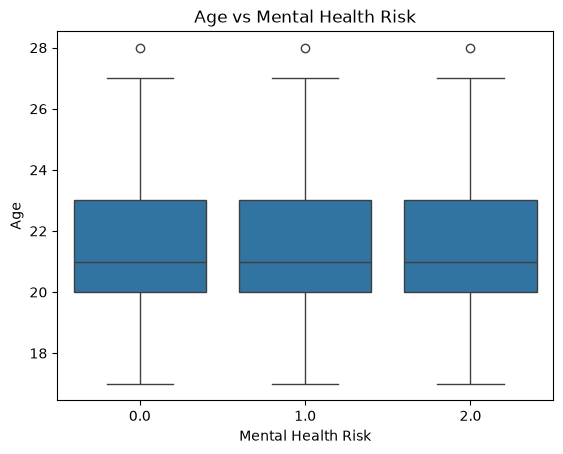

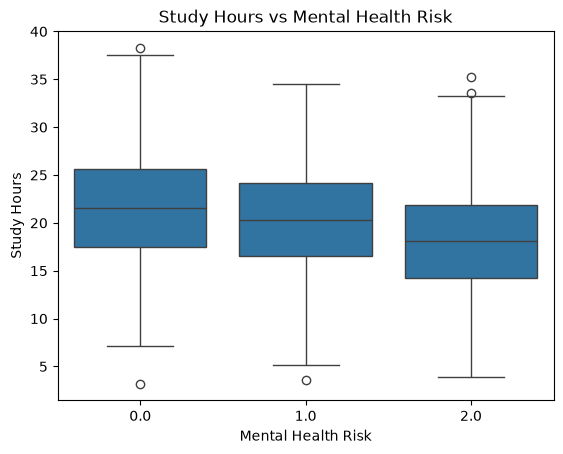

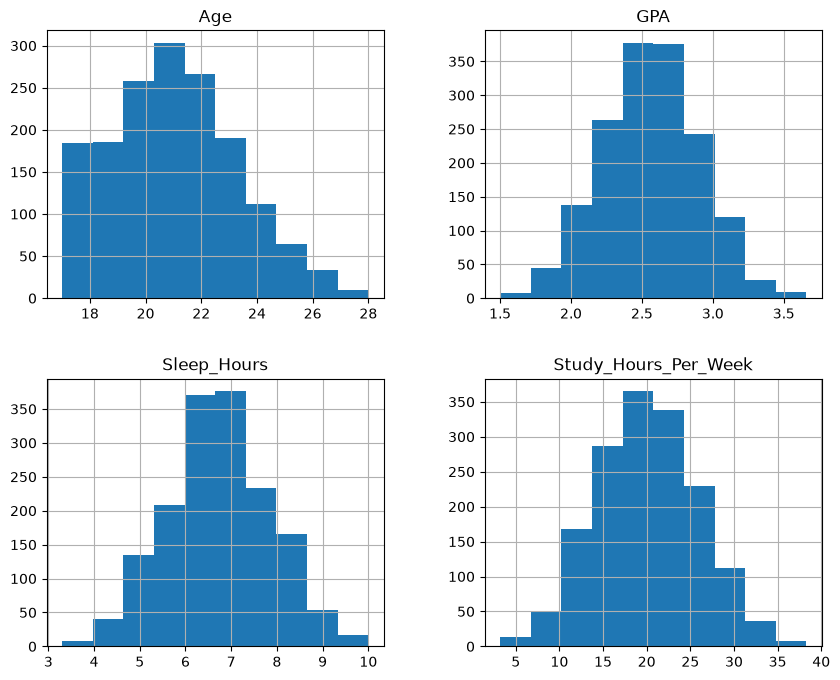

In [4]:
encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'High']])

df['Mental_Health_Risk'] = encoder.fit_transform(df[['Mental_Health_Risk']]).ravel()

df = pd.get_dummies(df, drop_first=True)

correlation_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

plt.figure(figsize=(10, 6))
sns.countplot(x='Mental_Health_Risk', data=df)
plt.title('Distribution of Mental Health Risk')
plt.xlabel('Mental Health Risk')
plt.ylabel('Count')
plt.show()

sns.boxplot(x='Mental_Health_Risk', y='Age', data=df)
plt.xlabel('Mental Health Risk')
plt.ylabel('Age')
plt.title('Age vs Mental Health Risk')
plt.show()

sns.boxplot(x='Mental_Health_Risk', y='Study_Hours_Per_Week', data=df)
plt.xlabel('Mental Health Risk')
plt.ylabel('Study Hours')
plt.title('Study Hours vs Mental Health Risk')
plt.show()

df[['Age', 'GPA', 'Sleep_Hours', 'Study_Hours_Per_Week']].hist(figsize=(10, 8))
plt.show()

In [5]:
features = ['Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Physical_Activity_Low', 'Physical_Activity_Moderate',
       'Part_Time_Job_Yes', 'Diet_Quality_Good', 'Diet_Quality_Poor', 'Previous_Mental_Health_History_Yes']
target = ["Mental_Health_Risk"]

X = df[features]
y = df['Mental_Health_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy:", model.score(X_test, y_test))

Accuracy: 0.7142857142857143
              precision    recall  f1-score   support

         0.0       0.77      0.79      0.78       101
         1.0       0.56      0.58      0.57       103
         2.0       0.82      0.76      0.79       118

    accuracy                           0.71       322
   macro avg       0.71      0.71      0.71       322
weighted avg       0.72      0.71      0.72       322

[[80 20  1]
 [24 60 19]
 [ 0 28 90]]
Train accuracy: 0.7344236760124611
Test accuracy: 0.7142857142857143


c:\Users\aymen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [6]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Train accuracy after imputation:", model.score(X_train, y_train))
print("Test accuracy after imputation:", model.score(X_test, y_test))


Train accuracy after imputation: 0.7344236760124611
Test accuracy after imputation: 0.7142857142857143


c:\Users\aymen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\aymen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate,Mental_Health_Risk,Physical_Activity_Low,Physical_Activity_Moderate,Part_Time_Job_Yes,Diet_Quality_Good,Diet_Quality_Poor,Previous_Mental_Health_History_Yes
0,22,3,6.6,17.6,2.91,6.9,7.5,8.5,4.0,78.0,2.0,False,True,False,False,True,False
1,21,4,5.6,22.4,2.92,7.6,11.5,4.5,5.3,85.4,1.0,True,False,True,False,False,False
2,22,5,7.1,28.1,2.68,6.5,8.9,4.8,6.1,79.5,1.0,True,False,False,False,False,False
3,24,1,4.5,14.8,2.23,5.5,7.6,3.7,8.0,73.9,2.0,False,False,False,False,False,True
6,24,2,7.7,15.0,2.77,8.8,10.2,6.1,7.7,100.0,0.0,True,False,False,True,False,False


Dimensions : (1606, 17)
Colonnes : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Mental_Health_Risk', 'Physical_Activity_Low', 'Physical_Activity_Moderate', 'Part_Time_Job_Yes', 'Diet_Quality_Good', 'Diet_Quality_Poor', 'Previous_Mental_Health_History_Yes']
<class 'pandas.DataFrame'>
Index: 1606 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 1606 non-null   int64  
 1   Year_of_Study                       1606 non-null   int64  
 2   Sleep_Hours                         1606 non-null   float64
 3   Study_Hours_Per_Week                1606 non-null   float64
 4   GPA                                 1606 non-null   float64
 5   Social_Media_Hours                  1606 non-null   float64
 6   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1606.0,NaN,NaN,NaN,21.129514,2.153757,17.0,20.0,21.0,23.0,28.0
Year_of_Study,1606.0,NaN,NaN,NaN,2.622042,1.315041,1.0,1.0,2.0,4.0,5.0
Sleep_Hours,1606.0,NaN,NaN,NaN,6.740535,1.115295,3.3,6.0,6.7,7.5,10.0
Study_Hours_Per_Week,1606.0,NaN,NaN,NaN,20.036239,5.775747,3.2,15.9,19.9,24.075,38.3
GPA,1606.0,NaN,NaN,NaN,2.561171,0.343064,1.5,2.33,2.56,2.79,3.66
Social_Media_Hours,1606.0,NaN,NaN,NaN,5.991968,1.155711,2.1,5.2,6.0,6.7,10.0
Screen_Time_Hours,1606.0,NaN,NaN,NaN,8.556787,1.667849,3.3,7.4,8.5,9.7,13.6
Financial_Stress,1606.0,NaN,NaN,NaN,5.930884,1.894048,1.5,4.5,6.05,7.4,10.0
Family_Support,1606.0,NaN,NaN,NaN,6.492839,1.863098,1.7,5.1,6.7,8.0,9.9
Attendance_Rate,1606.0,NaN,NaN,NaN,85.108095,7.145982,54.4,80.4,85.2,89.9,100.0


,Missing,Percentage
Age,0,0.0
Year_of_Study,0,0.0
Sleep_Hours,0,0.0
Study_Hours_Per_Week,0,0.0
GPA,0,0.0
Social_Media_Hours,0,0.0
Screen_Time_Hours,0,0.0
Financial_Stress,0,0.0
Family_Support,0,0.0
Attendance_Rate,0,0.0


Nombre de doublons : 0


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate,Mental_Health_Risk,Physical_Activity_Low,Physical_Activity_Moderate,Part_Time_Job_Yes,Diet_Quality_Good,Diet_Quality_Poor,Previous_Mental_Health_History_Yes


Age | Min : 17 | Max : 28
Year_of_Study | Min : 1 | Max : 5
Sleep_Hours | Min : 3.3 | Max : 10.0
Study_Hours_Per_Week | Min : 3.2 | Max : 38.3
GPA | Min : 1.5 | Max : 3.66
Social_Media_Hours | Min : 2.1 | Max : 10.0
Screen_Time_Hours | Min : 3.3 | Max : 13.6
Financial_Stress | Min : 1.5 | Max : 10.0
Family_Support | Min : 1.7 | Max : 9.9
Attendance_Rate | Min : 54.4 | Max : 100.0
Age : 3 outliers
Year_of_Study : 0 outliers
Sleep_Hours : 7 outliers
Study_Hours_Per_Week : 4 outliers
GPA : 7 outliers
Social_Media_Hours : 15 outliers
Screen_Time_Hours : 6 outliers
Financial_Stress : 0 outliers
Family_Support : 0 outliers
Attendance_Rate : 10 outliers


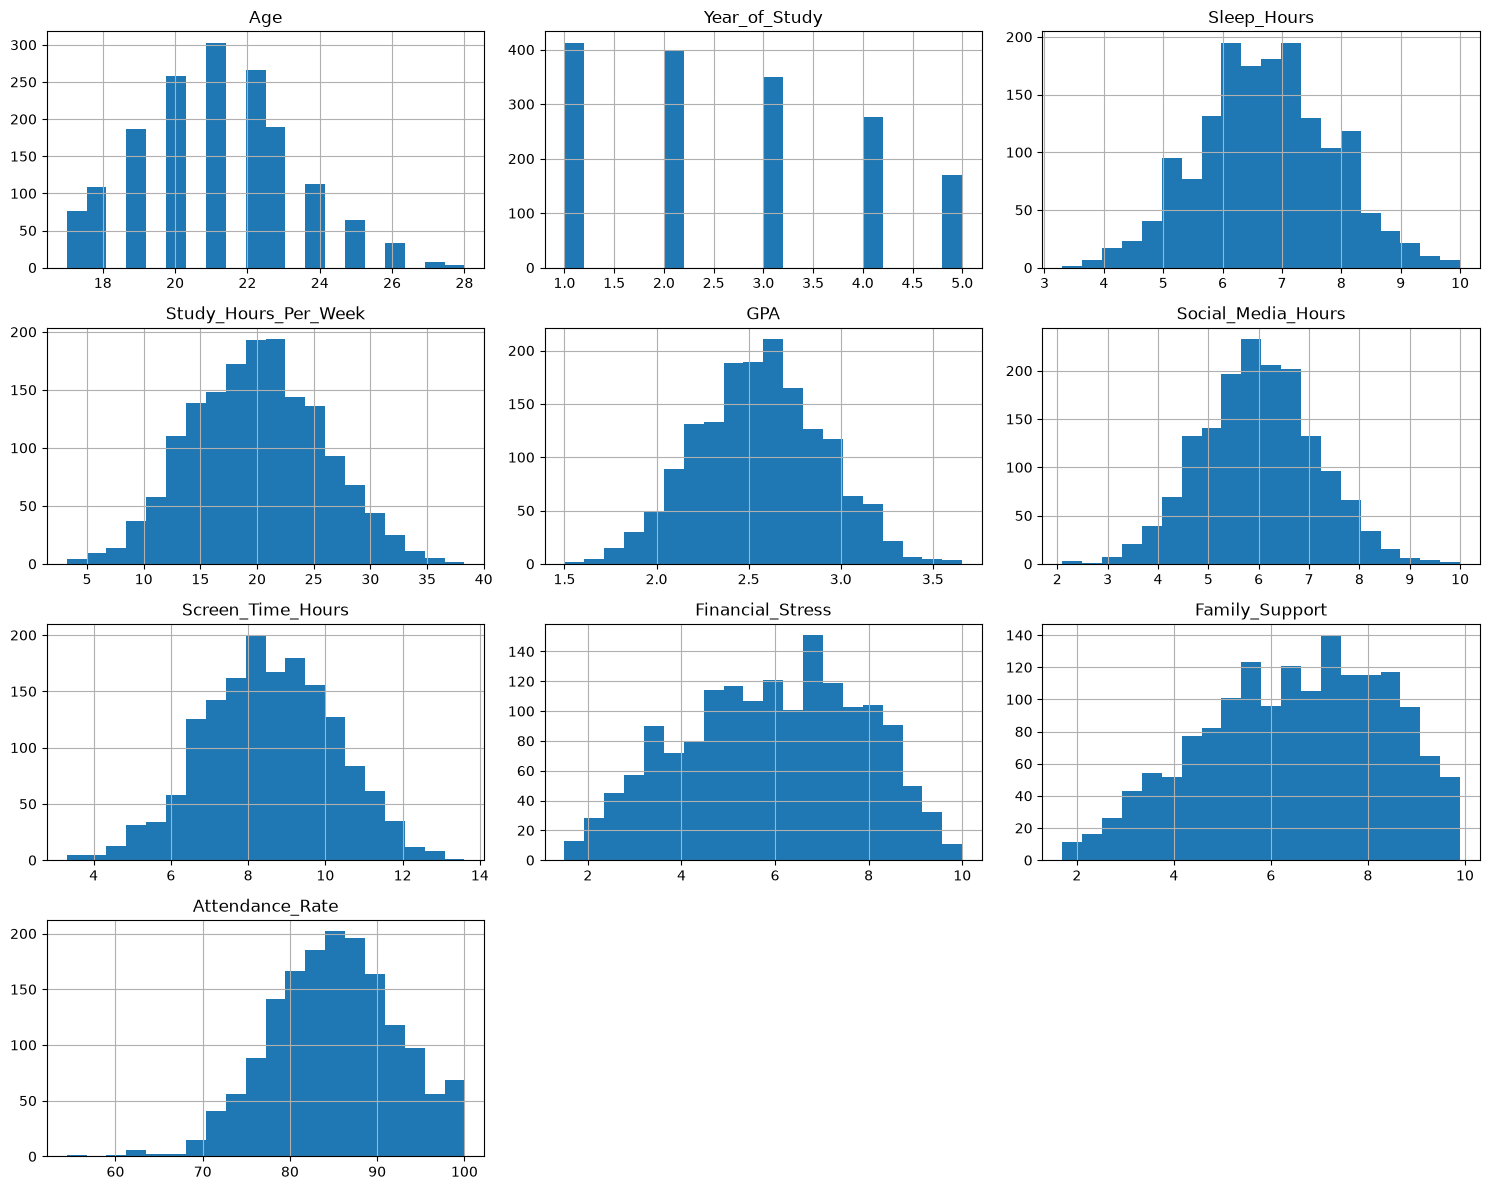

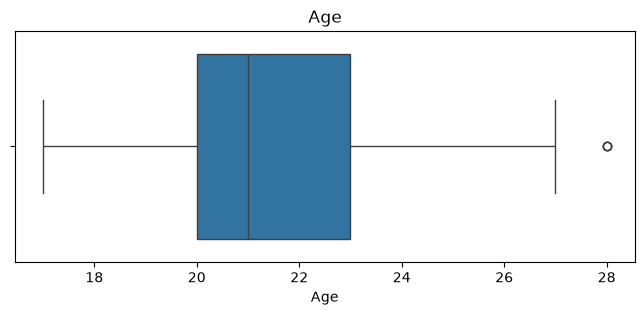

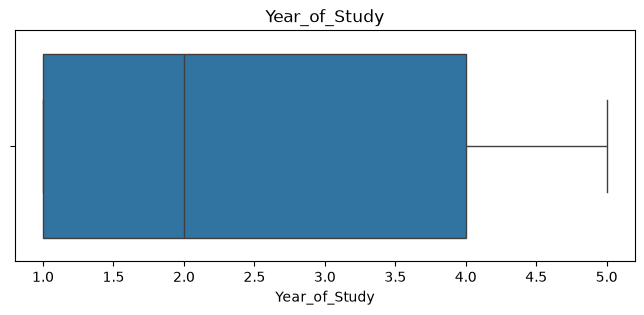

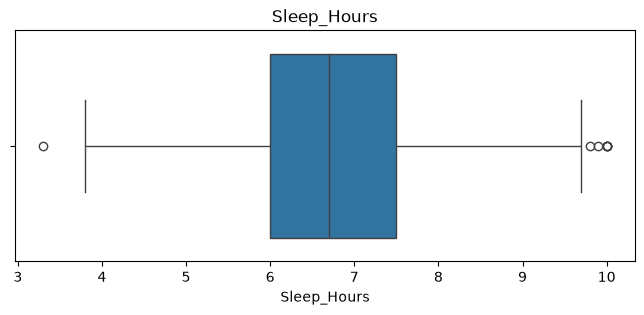

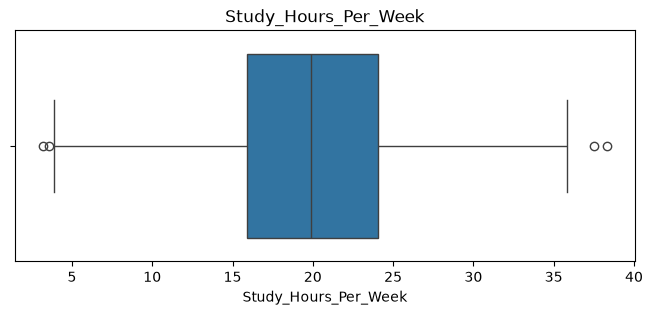

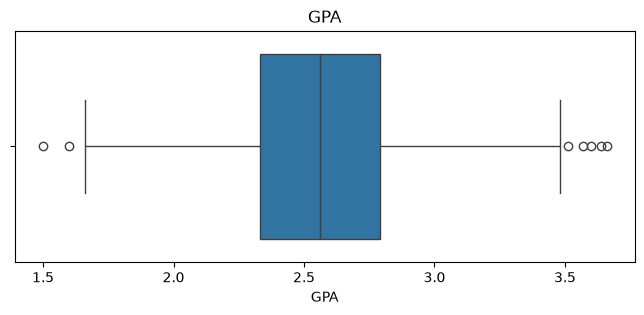

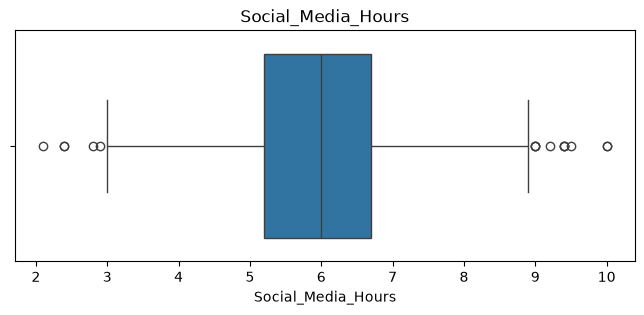

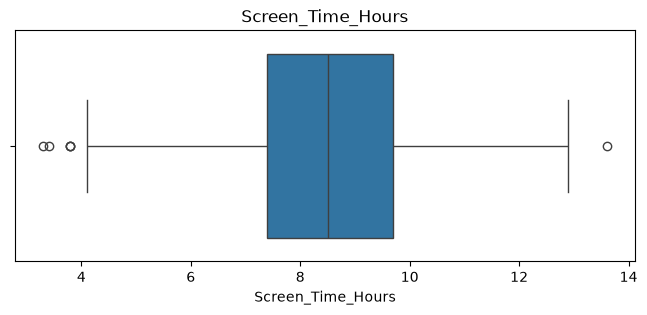

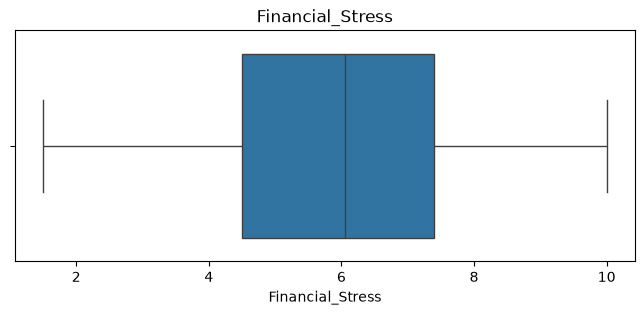

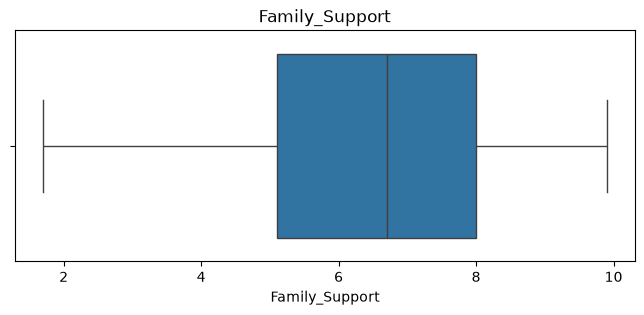

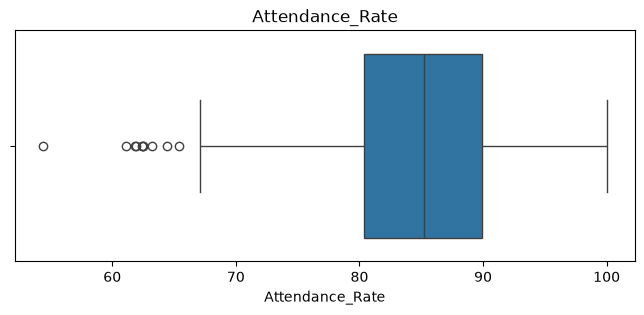

Mental_Health_Risk
2.0    557
0.0    529
1.0    520
Name: count, dtype: int64
Mental_Health_Risk
2.0    34.68
0.0    32.94
1.0    32.38
Name: proportion, dtype: float64


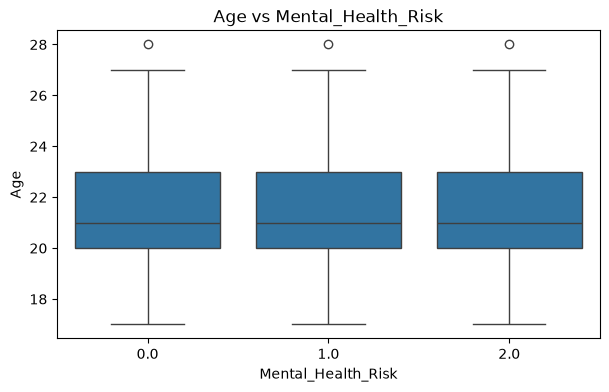

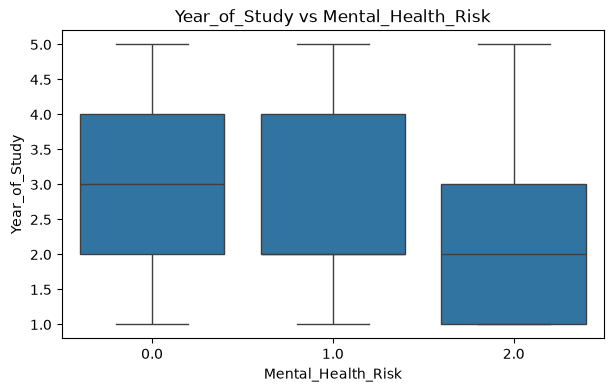

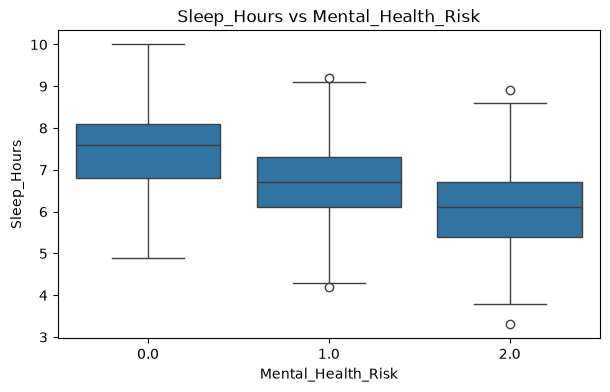

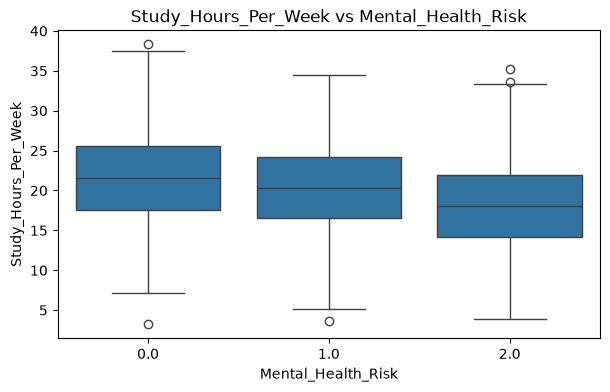

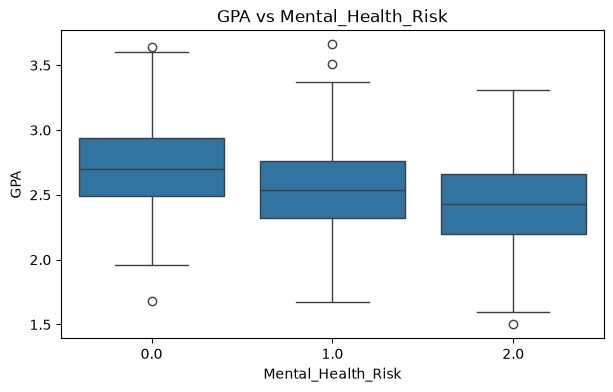

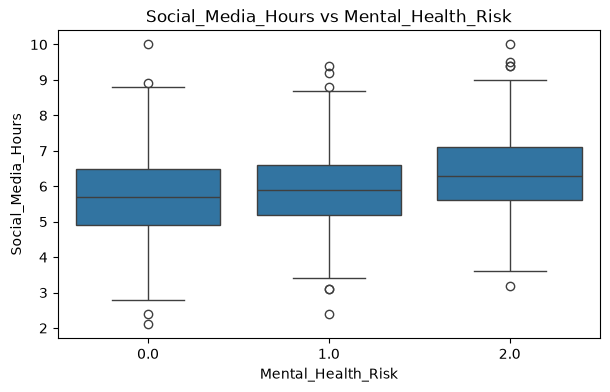

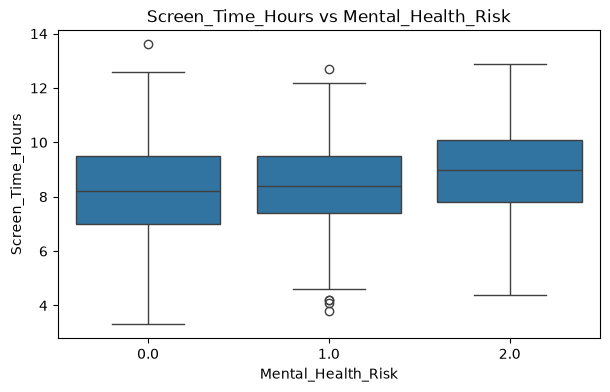

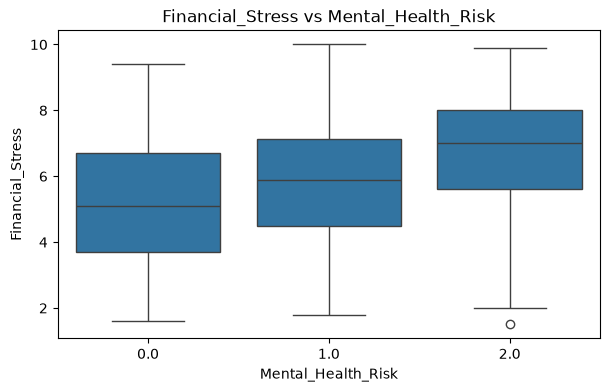

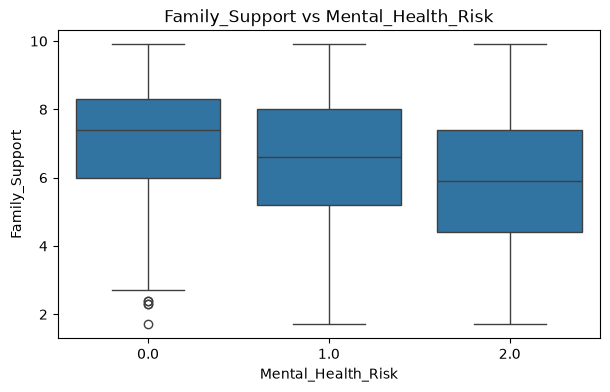

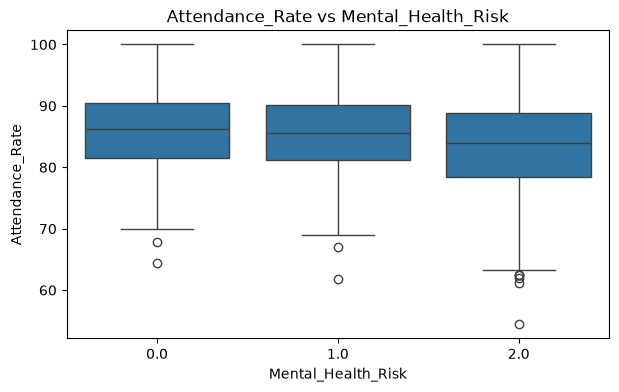

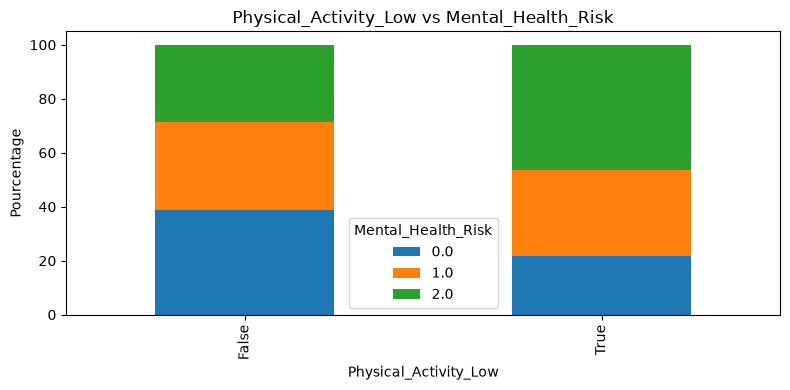

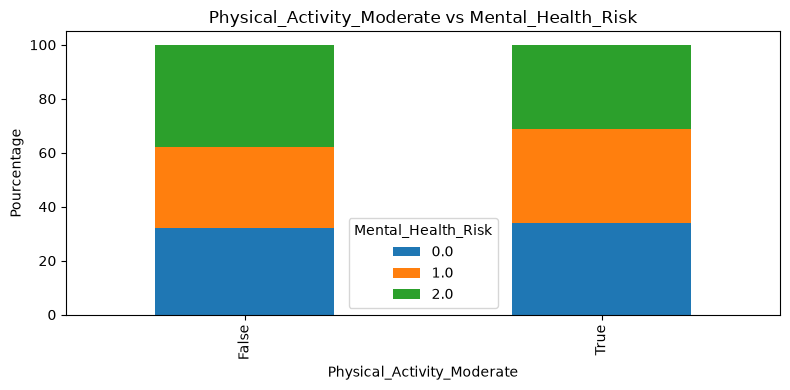

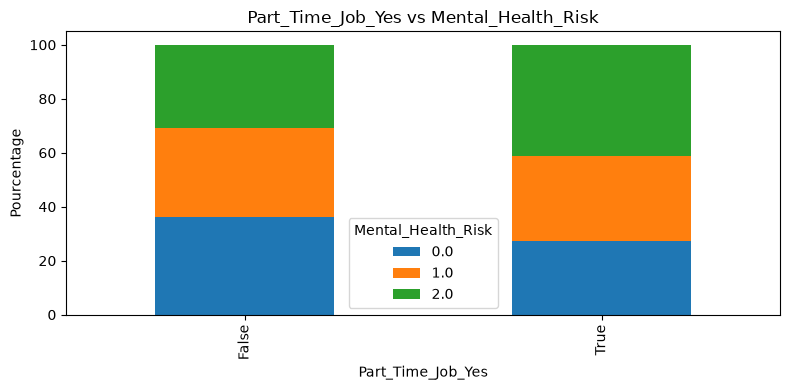

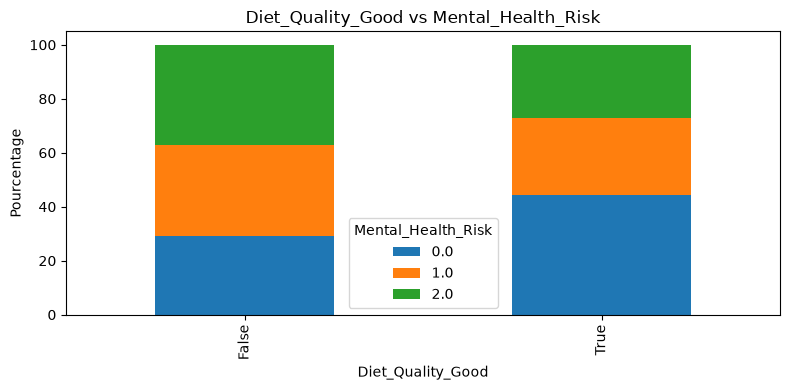

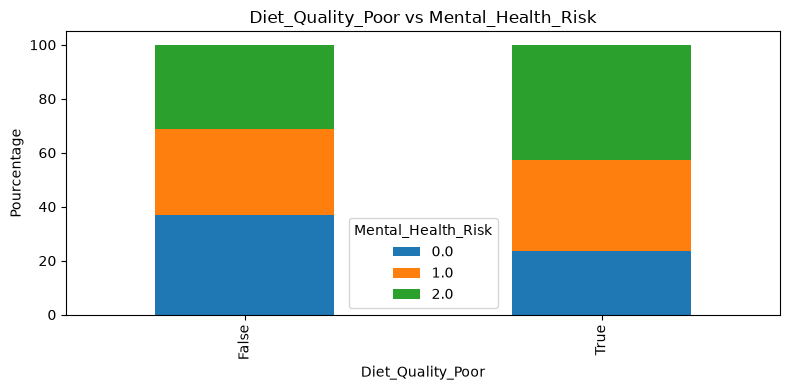

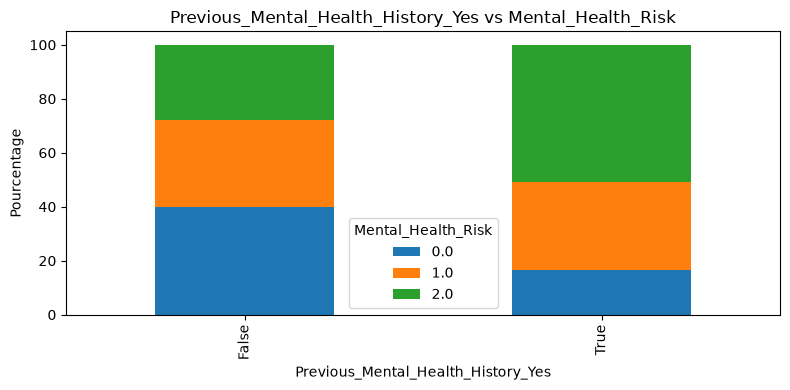

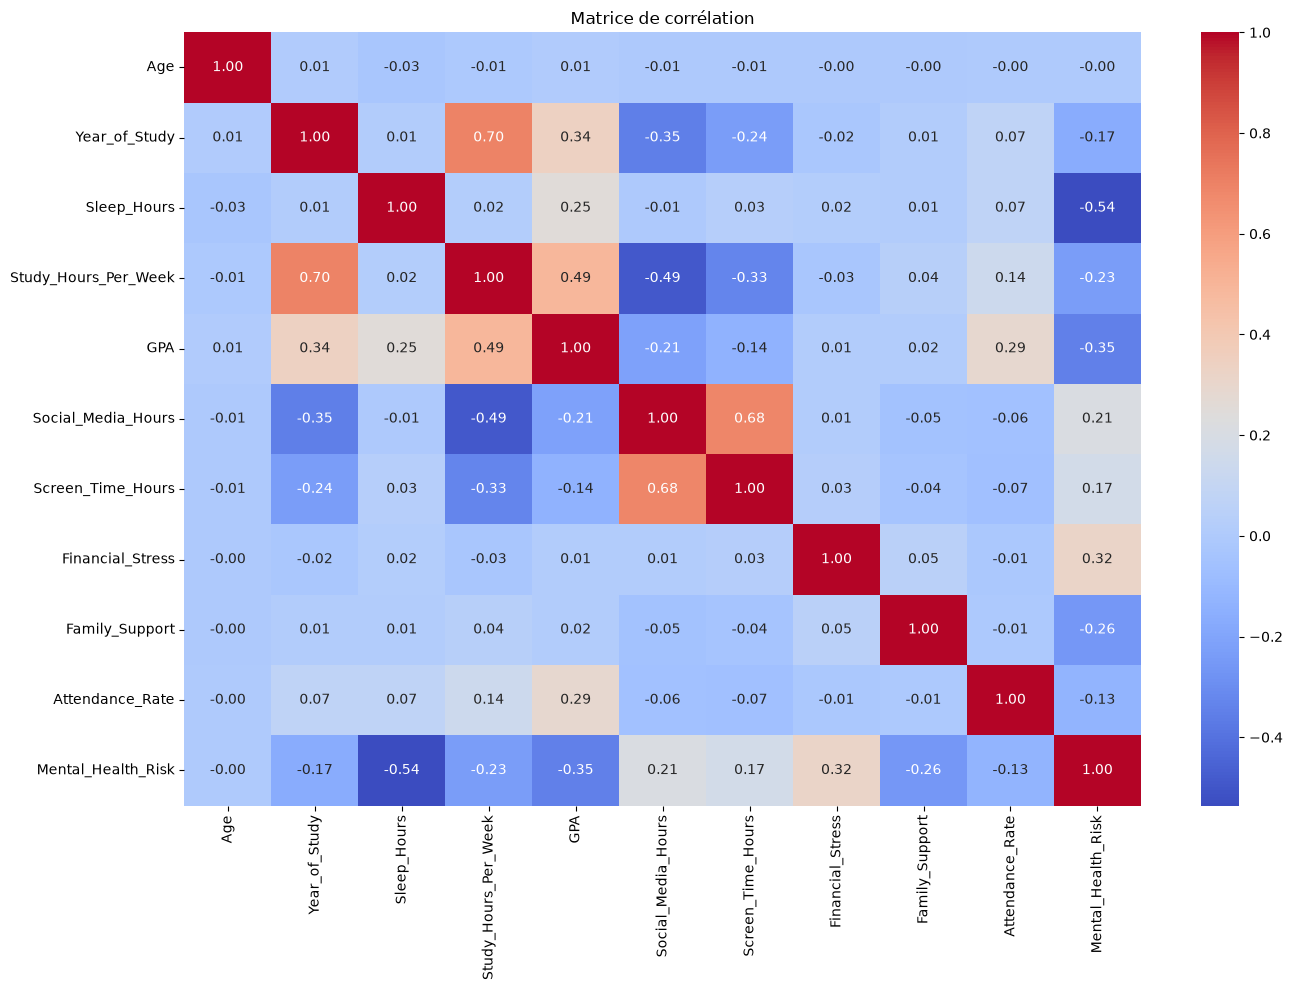

Sleep_Hours            -0.535780
GPA                    -0.349324
Financial_Stress        0.318730
Family_Support         -0.255369
Study_Hours_Per_Week   -0.233079
Social_Media_Hours      0.212475
Screen_Time_Hours       0.170664
Year_of_Study          -0.166160
Attendance_Rate        -0.132558
Age                    -0.001627
Name: Mental_Health_Risk, dtype: float64

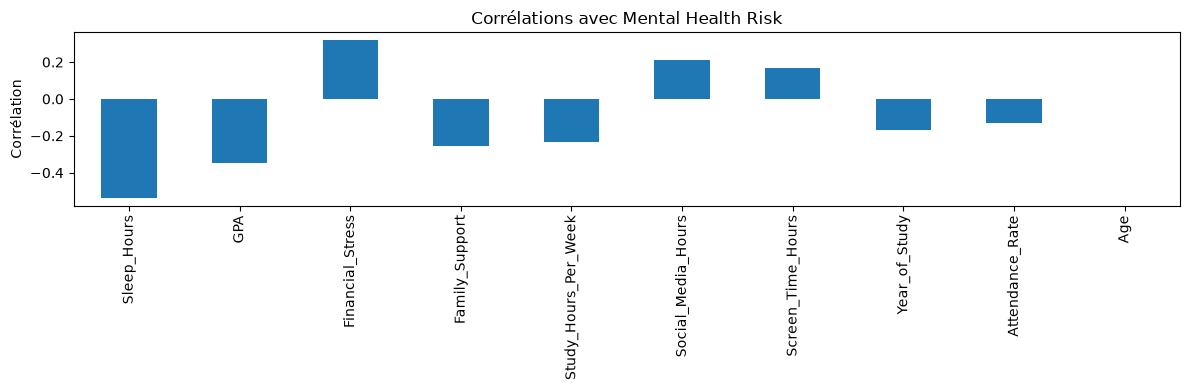

In [ ]:
target = target[0] if isinstance(target, (list, tuple)) else target

display(df.head())
print("Dimensions :", df.shape)
print("Colonnes :", df.columns)

df.info()
display(df.describe(include="all").T)

missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing)

print("Nombre de doublons :", df.duplicated().sum())

numerical_data = X.select_dtypes(include=["float32", "int64"]).columns
categorical_data = X.select_dtypes(include=["object", "category"]).columns

for col in numerical_data:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col, ":", len(outliers), "outliers")


numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] > 1:
    plt.figure(figsize=(14, 10))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Matrice de corrélation")
    plt.tight_layout()
    plt.show()

if pd.api.types.is_numeric_dtype(df[target]):
    correlations = numeric_df.corr()[target]
    correlations = correlations.drop(target).dropna()
    correlations = correlations.reindex(
        correlations.abs().sort_values(ascending=False).index
    )

    display(correlations)

    if len(correlations) > 0:
        plt.figure(figsize=(12, 4))
        correlations.plot(kind="bar")
        plt.title("Corrélations avec Mental Health Risk")
        plt.ylabel("Corrélation")
        plt.tight_layout()
        plt.show()
else:
    print("Cible catégorielle : consulter les analyses par groupe.")



Mental_Health_Risk
2.0    557
0.0    529
1.0    520
Name: count, dtype: int64


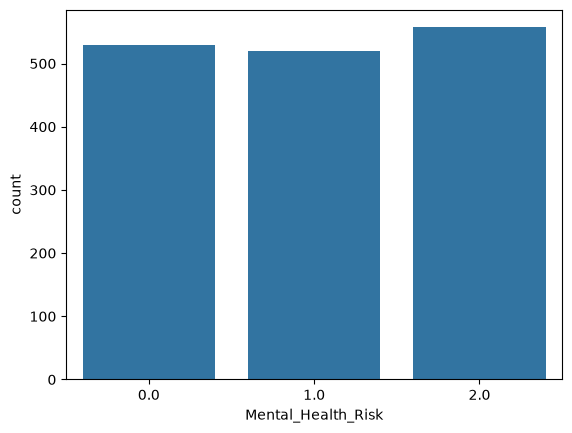

In [ ]:
print(df['Mental_Health_Risk'].value_counts())

sns.countplot(x='Mental_Health_Risk', data=df)
plt.show()

In [ ]:


preprocessing = ColumnTransformer([
    ("scaler", MinMaxScaler(), X),
    ("imputer", SimpleImputer(strategy="median"), X)
])

preprocessingNumerical = ColumnTransformer([
    ("std", StandardScaler(), numerical_data),
])

preprocessingCat = ColumnTransformer([
    ("oneh", OneHotEncoder(), categorical_data),
])

pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("preprocessingNumerical", preprocessingNumerical),
    ("preprocessingCat", preprocessingCat),
    ("model", SVC())
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model.fit(X_train, y_train)

print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy:", model.score(X_test, y_test))

Train accuracy: 0.7468847352024922
Test accuracy: 0.7204968944099379


c:\Users\aymen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
